In [1]:
base_path = "dataset"

In [2]:
import os

train_img_path = os.path.join(base_path, "train", "Color_Images")
train_mask_path = os.path.join(base_path, "train", "Segmentation")

print("Images:", len(os.listdir(train_img_path)))
print("Masks:", len(os.listdir(train_mask_path)))

Images: 2857
Masks: 2857


In [3]:
import pandas as pd

data = []

for img_name in os.listdir(train_img_path):
    img_path = os.path.join(train_img_path, img_name)
    mask_path = os.path.join(train_mask_path, img_name)

    if os.path.exists(mask_path):
        data.append([img_path, mask_path])
    else:
        print("Missing mask:", img_name)

train_df = pd.DataFrame(data, columns=["image", "mask"])

train_df.head()

,image,mask
0,dataset\train\Color_Images\cc0000012.png,dataset\train\Segmentation\cc0000012.png
1,dataset\train\Color_Images\cc0000013.png,dataset\train\Segmentation\cc0000013.png
2,dataset\train\Color_Images\cc0000014.png,dataset\train\Segmentation\cc0000014.png
3,dataset\train\Color_Images\cc0000015.png,dataset\train\Segmentation\cc0000015.png
4,dataset\train\Color_Images\cc0000017.png,dataset\train\Segmentation\cc0000017.png


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2857 entries, 0 to 2856
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   image   2857 non-null   object
 1   mask    2857 non-null   object
dtypes: object(2)
memory usage: 44.8+ KB


In [5]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [6]:
import cv2

img = cv2.imread(train_df.loc[0, "image"])
mask = cv2.imread(train_df.loc[0, "mask"], 0)

print("Image shape:", img.shape)
print("Mask shape:", mask.shape)


Image shape: (540, 960, 3)
Mask shape: (540, 960)


In [ ]:
import cv2
import numpy as np

heights = []
widths = []
channels = []

for i in range(len(train_df)):
    img = cv2.imread(train_df.loc[i, "image"])
    
    if img is None:
        print("Broken image:", train_df.loc[i, "image"])
        continue
    
    h, w, c = img.shape
    heights.append(h)
    widths.append(w)
    channels.append(c)

print("Unique Heights:", set(heights))
print("Unique Widths:", set(widths))
print("Unique Channels:", set(channels))

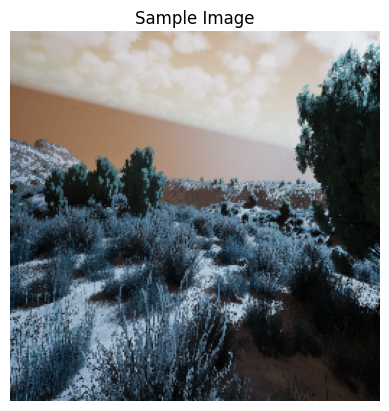

In [ ]:
plt.imshow(img)
plt.title("Sample Image")
plt.axis("off")
plt.show()

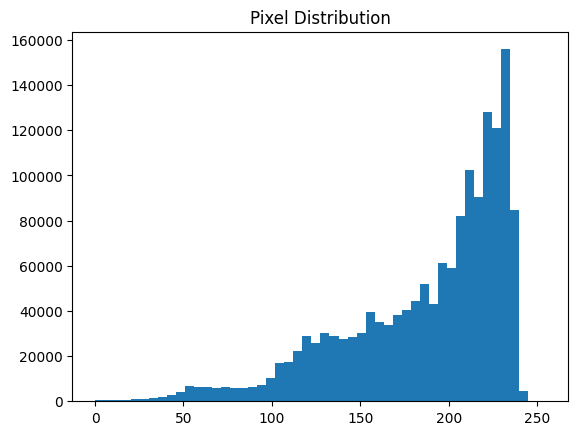

In [ ]:
import matplotlib.pyplot as plt

img = cv2.imread(train_df.loc[0, "image"])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.hist(img.ravel(), bins=50)
plt.title("Pixel Distribution")
plt.show()

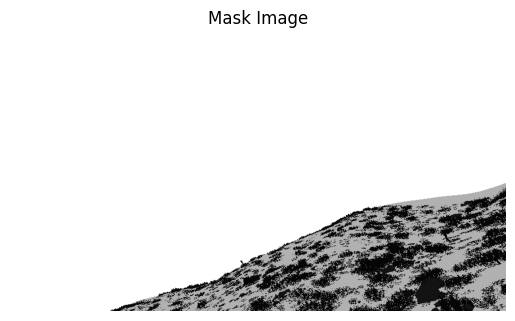

In [ ]:
mask = cv2.imread(train_df.loc[0, "mask"], 0)

plt.imshow(mask, cmap='gray')
plt.title("Mask Image")
plt.axis("off")
plt.show()

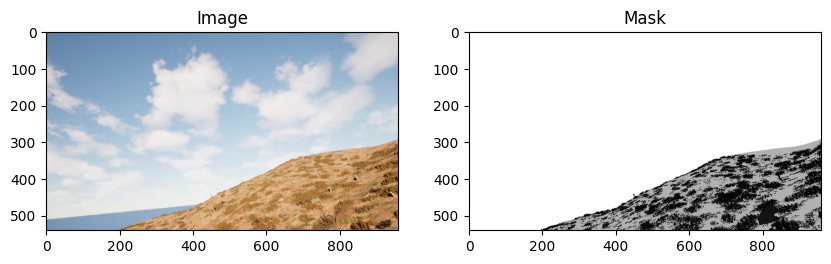

In [ ]:
img = cv2.imread(train_df.loc[0, "image"])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

mask = cv2.imread(train_df.loc[0, "mask"], 0)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(mask, cmap='gray')
plt.title("Mask")

plt.show()

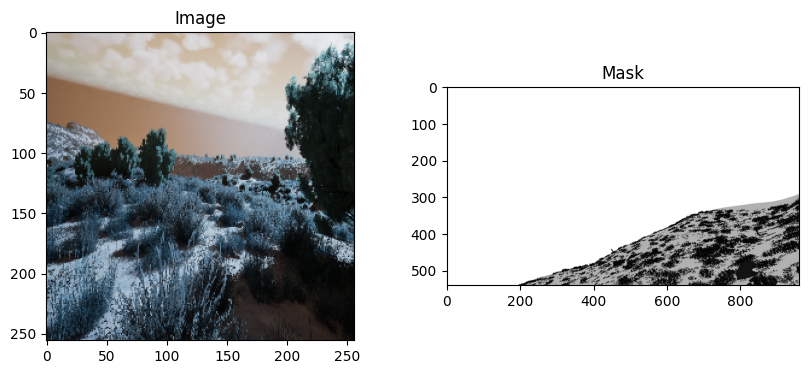

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(mask, cmap='gray')
plt.title("Mask")

plt.show()

In [ ]:
mask = cv2.imread(train_df.loc[0, "mask"], 0)

print("Unique mask values:", np.unique(mask))

Unique mask values: [ 0  1  2  3 27 39]


In [ ]:
IMG_SIZE = 256

img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))

In [ ]:
mask = cv2.imread(train_df.loc[0, "mask"], 0)

# convert to binary
_, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

print(np.unique(mask))

[0]


Min: 0
Max: 39
Unique (sample): [ 0  1  2  3 27 39]


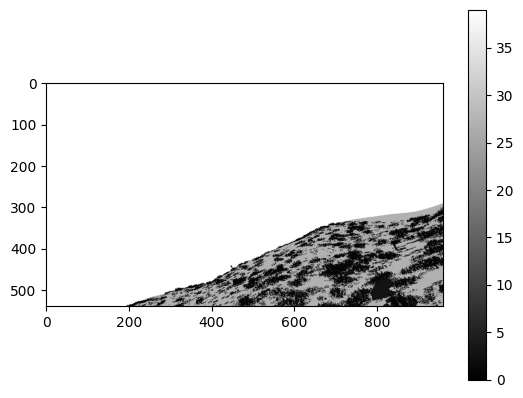

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

mask = cv2.imread(train_df.loc[0, "mask"], 0)

print("Min:", np.min(mask))
print("Max:", np.max(mask))
print("Unique (sample):", np.unique(mask)[:20])

plt.imshow(mask, cmap='gray')
plt.colorbar()
plt.show()

In [ ]:
import numpy as np
import cv2

mask = cv2.imread(train_df.loc[0, "mask"], 0)

# normalize values to 0–1 (binary assumption: anything >0 is object)
mask = (mask > 0).astype(np.uint8)

print(np.unique(mask))


[0 1]


In [ ]:
import numpy as np
import cv2

bad_masks = 0

for i in range(50):  # check first 50 (enough for validation)
    mask = cv2.imread(train_df.loc[i, "mask"], 0)
    mask = (mask > 0).astype(np.uint8)
    
    unique_vals = np.unique(mask)
    
    if not set(unique_vals).issubset({0,1}):
        print("Problem at index:", i, unique_vals)
        bad_masks += 1

print("Bad masks count:", bad_masks)

Bad masks count: 0


In [ ]:
import cv2

IMG_SIZE = 256

def preprocess(image_path, mask_path):
    # read
    img = cv2.imread(image_path)
    mask = cv2.imread(mask_path, 0)
    
    # resize
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    
    # normalize
    img = img / 255.0
    
    # binary mask
    mask = (mask > 0).astype("float32")
    
    return img, mask

In [ ]:
img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

print(img.shape, mask.shape)
print(mask.min(), mask.max())

(256, 256, 3) (256, 256)
0.0 1.0


In [ ]:
import numpy as np

def data_generator(df, batch_size=8):
    while True:
        for i in range(0, len(df), batch_size):
            batch = df.iloc[i:i+batch_size]
            
            imgs = []
            masks = []
            
            for _, row in batch.iterrows():
                img, mask = preprocess(row["image"], row["mask"])
                
                imgs.append(img)
                masks.append(mask)
            
            imgs = np.array(imgs)
            masks = np.array(masks)
            
            # add channel to mask (important)
            masks = np.expand_dims(masks, axis=-1)
            
            yield imgs, masks

In [ ]:
gen = data_generator(train_df, batch_size=4)

x, y = next(gen)

print(x.shape)   # images
print(y.shape)   # masks

(4, 256, 256, 3)
(4, 256, 256, 1)


In [ ]:
pip install tensorflow


Note: you may need to restart the kernel to use updated packages.


In [ ]:
from tensorflow.keras import layers, models

def unet_model(input_size=(256, 256, 3)):
    inputs = layers.Input(input_size)

    # Encoder
    c1 = layers.Conv2D(16, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(16, 3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D()(c1)

    c2 = layers.Conv2D(32, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(32, 3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D()(c2)

    c3 = layers.Conv2D(64, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(64, 3, activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D()(c3)

    # Bottleneck
    c4 = layers.Conv2D(128, 3, activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(128, 3, activation='relu', padding='same')(c4)

    # Decoder
    u5 = layers.UpSampling2D()(c4)
    u5 = layers.concatenate([u5, c3])
    c5 = layers.Conv2D(64, 3, activation='relu', padding='same')(u5)
    c5 = layers.Conv2D(64, 3, activation='relu', padding='same')(c5)

    u6 = layers.UpSampling2D()(c5)
    u6 = layers.concatenate([u6, c2])
    c6 = layers.Conv2D(32, 3, activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(32, 3, activation='relu', padding='same')(c6)

    u7 = layers.UpSampling2D()(c6)
    u7 = layers.concatenate([u7, c1])
    c7 = layers.Conv2D(16, 3, activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(16, 3, activation='relu', padding='same')(c7)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c7)

    model = models.Model(inputs, outputs)
    return model


model = unet_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_9[0][0]  

 Total params: 487,297 (1.86 MB)

 Trainable params: 487,297 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


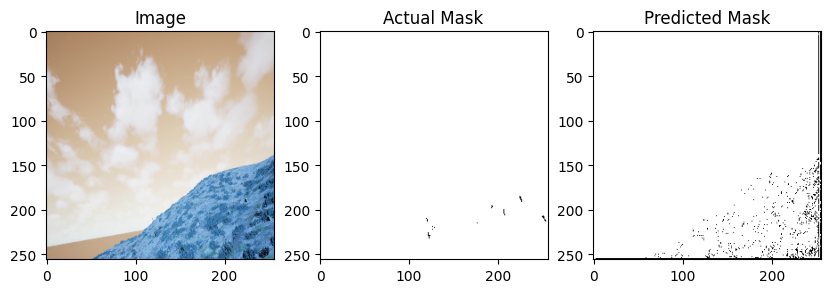

In [ ]:
import matplotlib.pyplot as plt

# take one sample
img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

# model prediction
pred = model.predict(img.reshape(1, 256, 256, 3))[0]

# convert prediction to binary
pred = (pred > 0.5).astype("uint8")

# plot
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(mask, cmap='gray')
plt.title("Actual Mask")

plt.subplot(1,3,3)
plt.imshow(pred.squeeze(), cmap='gray')
plt.title("Predicted Mask")

plt.show()

In [ ]:
import numpy as np
import cv2

ratios = []

for i in range(100):  # check 100 samples
    mask = cv2.imread(train_df.loc[i, "mask"], 0)
    mask = (mask > 0).astype(np.uint8)
    
    ratio = np.sum(mask) / mask.size
    ratios.append(ratio)

print("Min ratio:", min(ratios))
print("Max ratio:", max(ratios))
print("Avg ratio:", sum(ratios)/len(ratios))

Min ratio: 0.996778549382716
Max ratio: 0.9993055555555556
Avg ratio: 0.9983690393518517


In [ ]:
mask = cv2.imread(train_df.loc[0, "mask"], 0)

# invert mask
mask = (mask > 0).astype("float32")

print(np.unique(mask))

[0. 1.]


In [ ]:
small_df = train_df.sample(200)   # only 200 images

small_gen = data_generator(small_df, batch_size=8)

steps = len(small_df) // 8

history = model.fit(
    small_gen,
    steps_per_epoch=steps,
    epochs=3
)

Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.9019 - loss: 0.3968
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 21s 840ms/step - accuracy: 0.9063 - loss: 0.2808
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 768ms/step - accuracy: 0.9063 - loss: 0.2564


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step


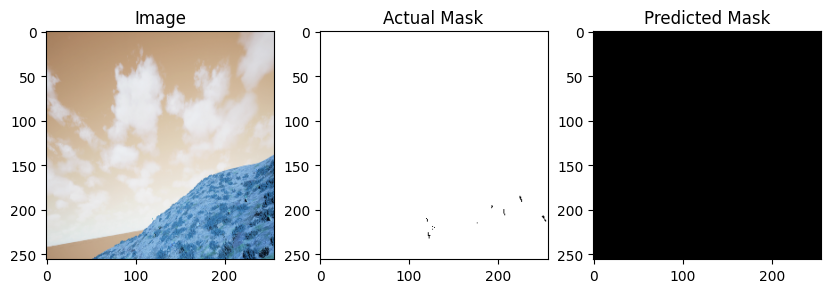

In [ ]:
import matplotlib.pyplot as plt

# take one sample
img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

# model prediction
pred = model.predict(img.reshape(1, 256, 256, 3))[0]

# convert prediction to binary
pred = (pred > 0.5).astype("uint8")

# plot
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(mask, cmap='gray')
plt.title("Actual Mask")

plt.subplot(1,3,3)
plt.imshow(pred.squeeze(), cmap='gray')
plt.title("Predicted Mask")

plt.show()

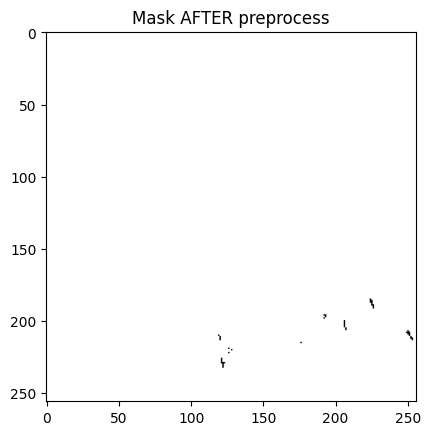

Unique: {np.float32(0.0), np.float32(1.0)}


In [ ]:
import matplotlib.pyplot as plt

img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

plt.imshow(mask, cmap='gray')
plt.title("Mask AFTER preprocess")
plt.show()

print("Unique:", set(mask.flatten()))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


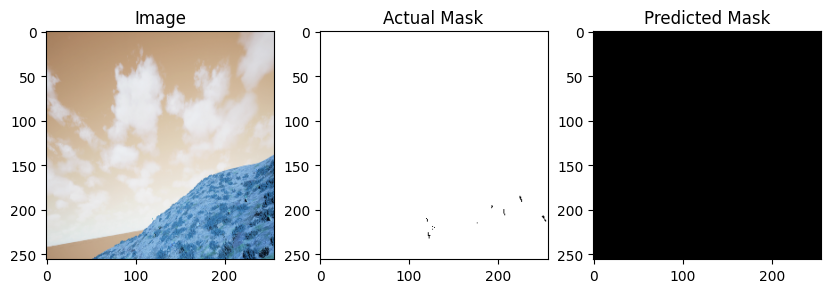

In [ ]:
import matplotlib.pyplot as plt

# take one sample
img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

# model prediction
pred = model.predict(img.reshape(1, 256, 256, 3))[0]

# convert prediction to binary
pred = (pred > 0.5).astype("uint8")


# plot
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(mask, cmap='gray')
plt.title("Actual Mask")

plt.subplot(1,3,3)
plt.imshow(pred.squeeze(), cmap='gray')
plt.title("Predicted Mask")

plt.show()

In [ ]:
import tensorflow as tf

def weighted_bce(y_true, y_pred):
    weight_for_1 = 5.0   # increase importance of object
    weight_for_0 = 1.0

    bce = tf.keras.backend.binary_crossentropy(y_true, y_pred)
    
    weights = y_true * weight_for_1 + (1 - y_true) * weight_for_0
    weighted_bce = weights * bce

    return tf.reduce_mean(weighted_bce)


model.compile(
    optimizer='adam',
    loss=weighted_bce,
    metrics=['accuracy']
)

In [ ]:
small_df = train_df.sample(200)   # only 200 images

small_gen = data_generator(small_df, batch_size=8)

steps = len(small_df) // 8

history = model.fit(
    small_gen,
    steps_per_epoch=steps,
    epochs=5
    
)

Epoch 1/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 30s 833ms/step - accuracy: 0.9078 - loss: 0.3789
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 875ms/step - accuracy: 0.9078 - loss: 0.3207
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 719ms/step - accuracy: 0.9078 - loss: 0.3078
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 691ms/step - accuracy: 0.9078 - loss: 0.2955
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 687ms/step - accuracy: 0.9078 - loss: 0.3096


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


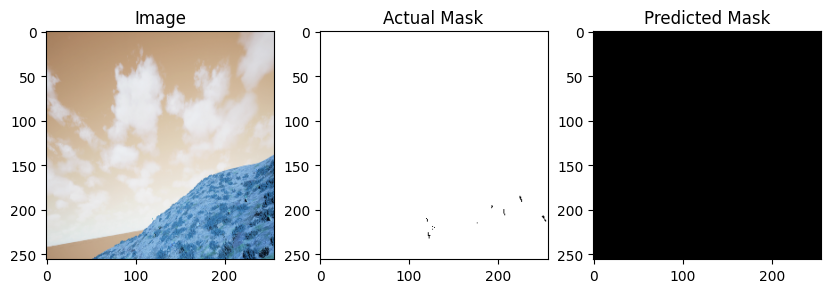

In [ ]:

import matplotlib.pyplot as plt

# take one sample
img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

# model prediction
pred = model.predict(img.reshape(1, 256, 256, 3))[0]

# convert prediction to binary
pred = (pred > 0.5).astype("uint8")

# plot
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(mask, cmap='gray')
plt.title("Actual Mask")

plt.subplot(1,3,3)
plt.imshow(pred.squeeze(), cmap='gray')
plt.title("Predicted Mask")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 524ms/step


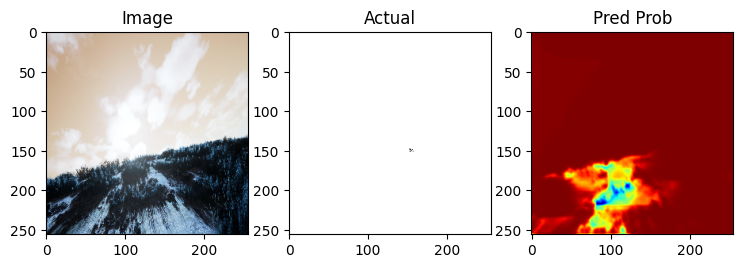

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


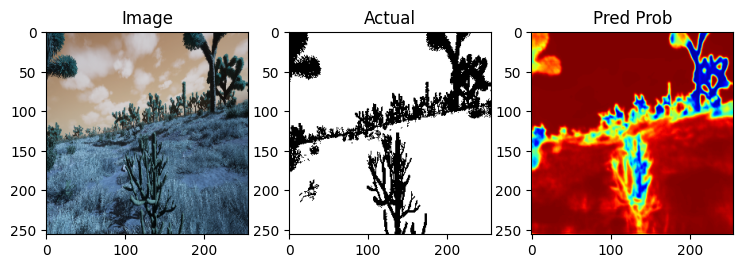

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step


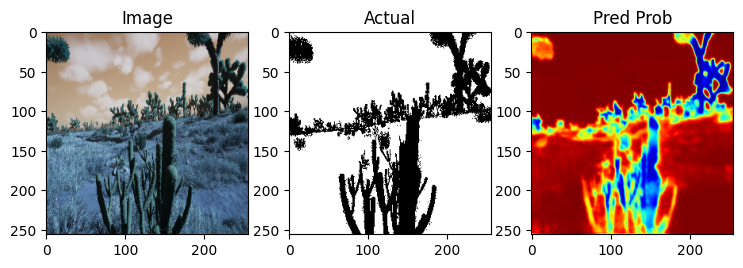

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


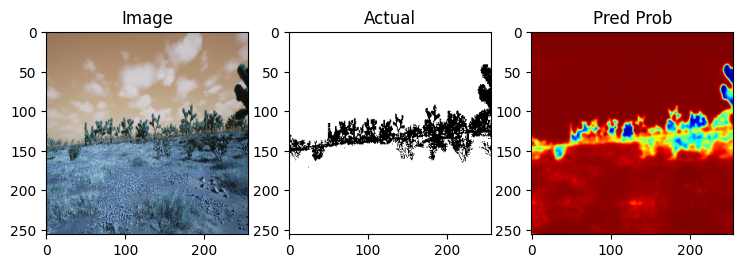

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step


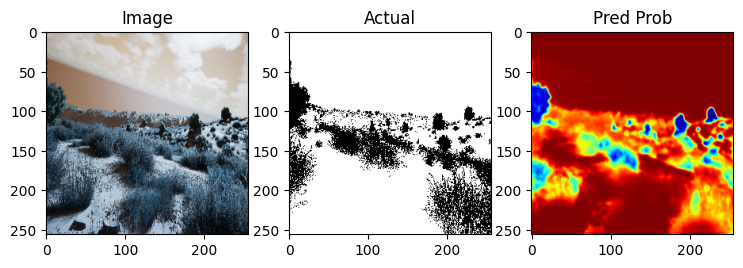

In [ ]:
import matplotlib.pyplot as plt
import random

# check 5 random samples
indices = random.sample(range(len(train_df)), 5)

for i in indices:
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1, 256, 256, 3))[0]
    
    # raw prediction (before threshold)
    pred_raw = pred.squeeze()
    
    # binary prediction
    pred_bin = (pred_raw > 0.5).astype("uint8")
    
    plt.figure(figsize=(12,4))
    
    plt.subplot(1,4,1)
    plt.imshow(img)
    plt.title("Image")
    
    plt.subplot(1,4,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Actual")
    
    plt.subplot(1,4,3)
    plt.imshow(pred_raw, cmap='jet')
    plt.title("Pred Prob")
    
    
    plt.show()

In [ ]:
small_df = train_df.sample(200)   # only 200 images

small_gen = data_generator(small_df, batch_size=8)

steps = len(small_df) // 8

history = model.fit(
    small_gen,
    steps_per_epoch=steps,
    epochs=3
    
)

Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 705ms/step - accuracy: 0.9127 - loss: 0.2691
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 694ms/step - accuracy: 0.9127 - loss: 0.2543
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 731ms/step - accuracy: 0.9132 - loss: 0.2545


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step


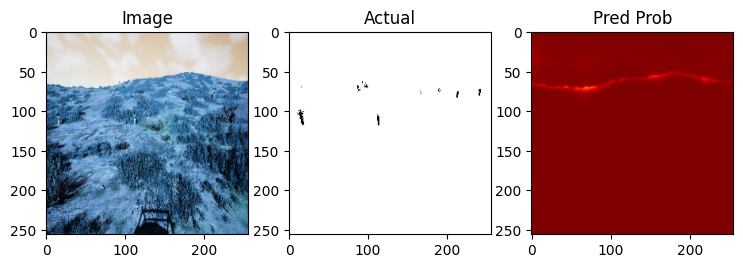

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


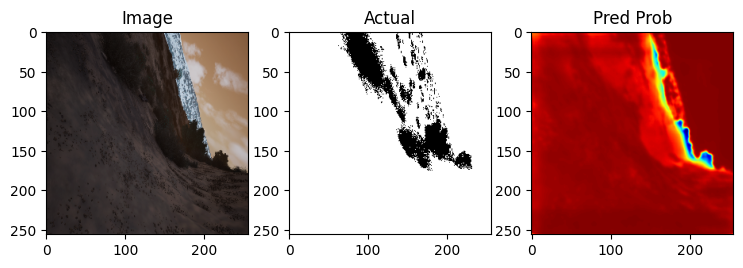

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


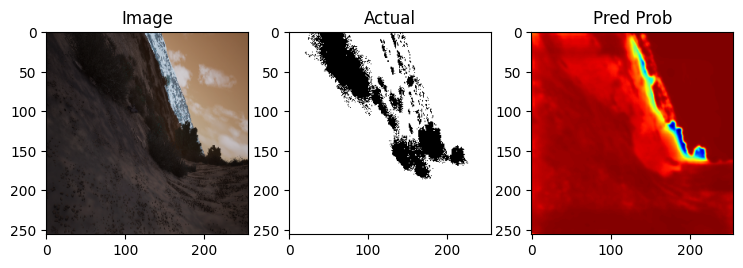

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


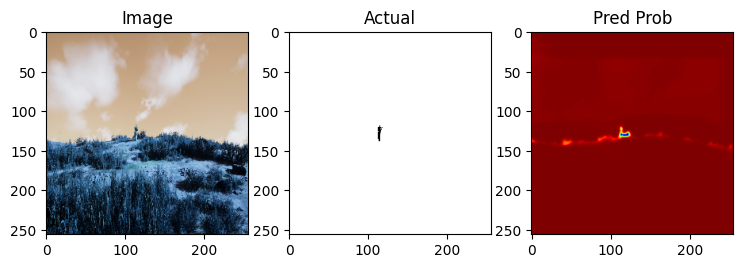

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


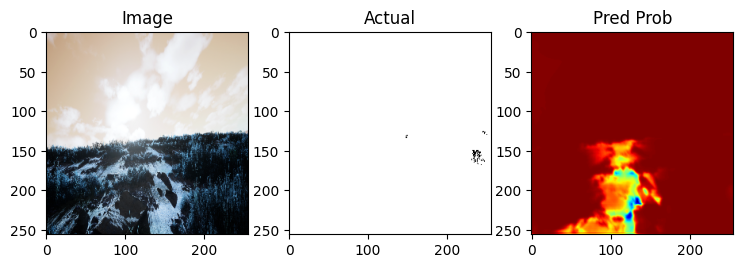

In [ ]:
import matplotlib.pyplot as plt
import random

# check 5 random samples
indices = random.sample(range(len(train_df)), 5)

for i in indices:
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1, 256, 256, 3))[0]
    
    # raw prediction (before threshold)
    pred_raw = pred.squeeze()
    
    # binary prediction
    pred_bin = (pred_raw > 0.5).astype("uint8")
    
    plt.figure(figsize=(12,4))
    
    plt.subplot(1,4,1)
    plt.imshow(img)
    plt.title("Image")
    
    plt.subplot(1,4,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Actual")
    
    plt.subplot(1,4,3)
    plt.imshow(pred_raw, cmap='jet')
    plt.title("Pred Prob")

    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


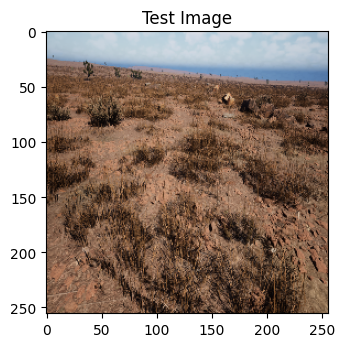

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


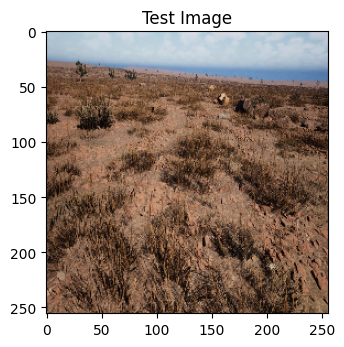

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


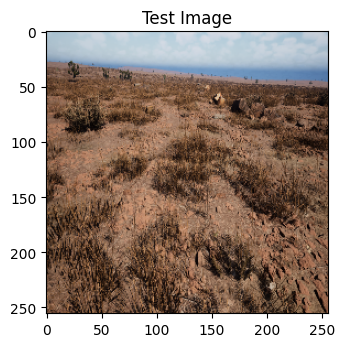

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


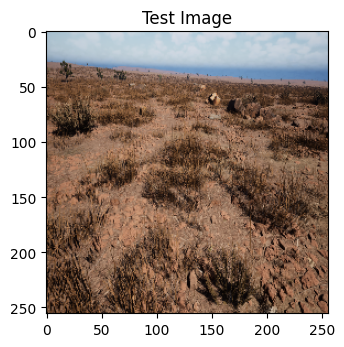

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


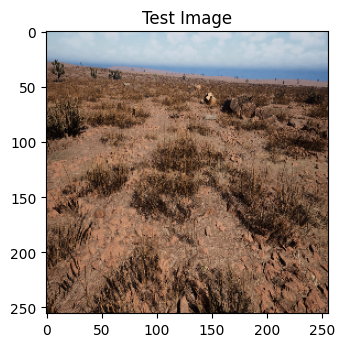

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

test_path = "dataset/test/Color_Images"

test_images = os.listdir(test_path)

# show 5 predictions
for img_name in test_images[:5]:
    img_path = os.path.join(test_path, img_name)
    
    # preprocess image (no mask here)
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    # prediction
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    
    pred = (pred > 0.2).astype("uint8")   # lower threshold
    
    # plot
    plt.figure(figsize=(8,4))
    
    plt.subplot(1,2,1)
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.title("Test Image")
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


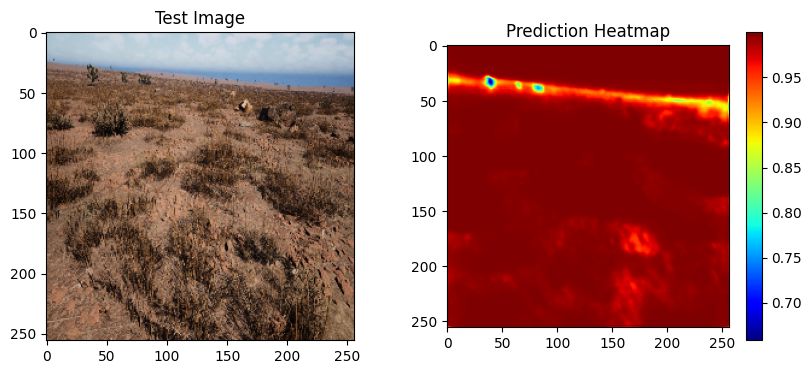

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


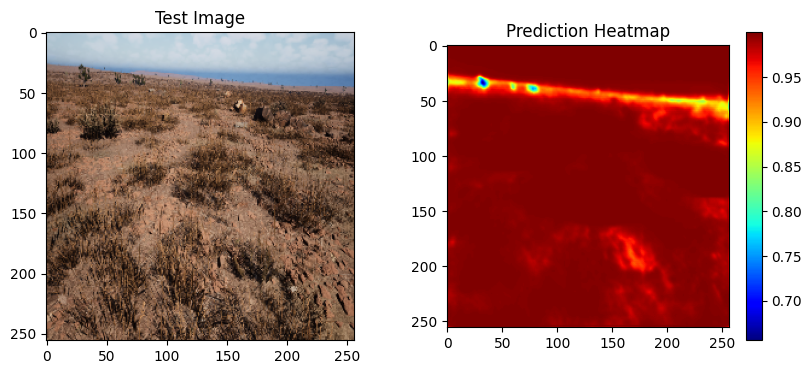

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


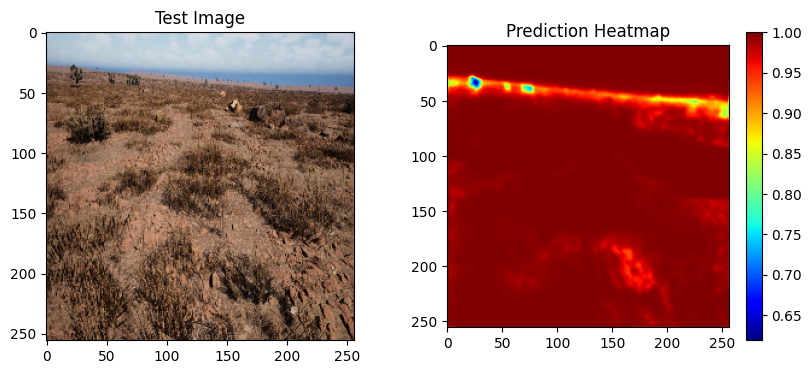

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step


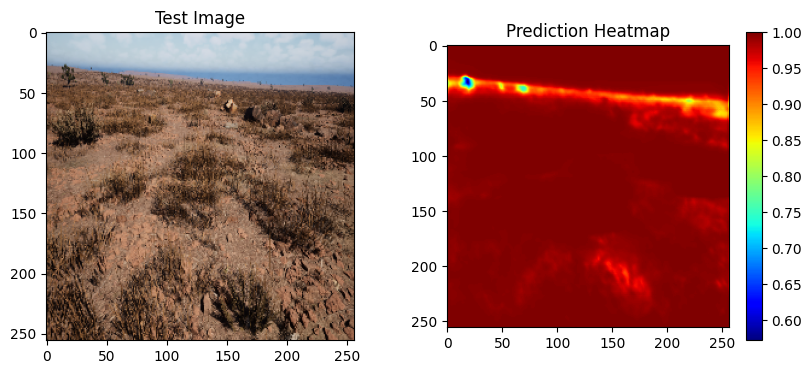

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step


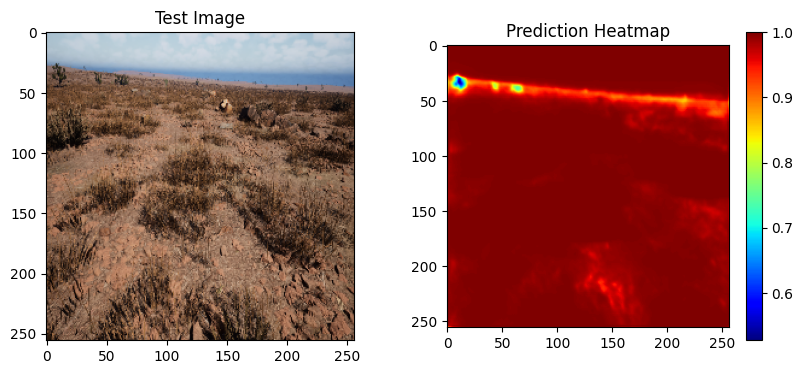

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

for img_name in test_images[:5]:
    img_path = os.path.join(test_path, img_name)
    
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    plt.figure(figsize=(10,4))
    
    # original image
    plt.subplot(1,2,1)
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.title("Test Image")
    
    # heatmap
    plt.subplot(1,2,2)
    plt.imshow(pred_raw, cmap='jet')   # KEY LINE
    plt.colorbar()
    plt.title("Prediction Heatmap")
    
    plt.show()

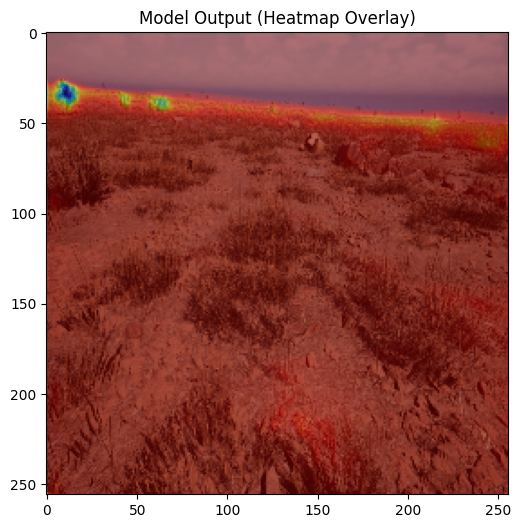

In [ ]:
plt.figure(figsize=(6,6))

plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
plt.imshow(pred_raw, cmap='jet', alpha=0.5)   # overlay
plt.title("Model Output (Heatmap Overlay)")

plt.show()

In [ ]:
import numpy as np
import cv2

def iou_score(y_true, y_pred):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()
    
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    
    return intersection / (union + 1e-6)

In [ ]:
scores = []

for i in range(20):
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred = (pred > 0.2).astype("uint8").squeeze()
    
    score = iou_score(mask, pred)
    scores.append(score)

print("Average IoU:", sum(scores)/len(scores))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
Average IoU: 0.9989974975433504


In [ ]:
def foreground_iou(y_true, y_pred):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()
    
    # consider only object pixels
    intersection = np.sum((y_true == 1) & (y_pred == 1))
    union = np.sum((y_true == 1) | (y_pred == 1))
    
    return intersection / (union + 1e-6)

In [ ]:
scores = []

for i in range(20):
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred = (pred > 0.2).astype("uint8").squeeze()
    
    score = foreground_iou(mask, pred)
    scores.append(score)

print("Foreground IoU:", sum(scores)/len(scores))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Foreground IoU: 0.9989974975433504


In [ ]:
scores = []

for i in range(20):
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    # FIX: make mask binary
    mask = (mask > 0.5).astype("uint8")
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred = (pred > 0.2).astype("uint8").squeeze()
    
    score = foreground_iou(mask, pred)
    scores.append(score)

print("Foreground IoU:", sum(scores)/len(scores))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Foreground IoU: 0.9989974975433504


In [ ]:
import numpy as np

img, mask = preprocess(train_df.loc[0, "image"], train_df.loc[0, "mask"])

# make mask binary
mask_bin = (mask > 0.5).astype("uint8")

pred = model.predict(img.reshape(1,256,256,3))[0]
pred_bin = (pred > 0.2).astype("uint8").squeeze()

print("Mask unique:", np.unique(mask_bin))
print("Pred unique:", np.unique(pred_bin))

print("Mask sum:", np.sum(mask_bin))
print("Pred sum:", np.sum(pred_bin))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Mask unique: [0 1]
Pred unique: [1]
Mask sum: 65487
Pred sum: 65536


In [ ]:
diff = np.abs(mask_bin - pred_bin)

print("Different pixels:", np.sum(diff))

Different pixels: 12495


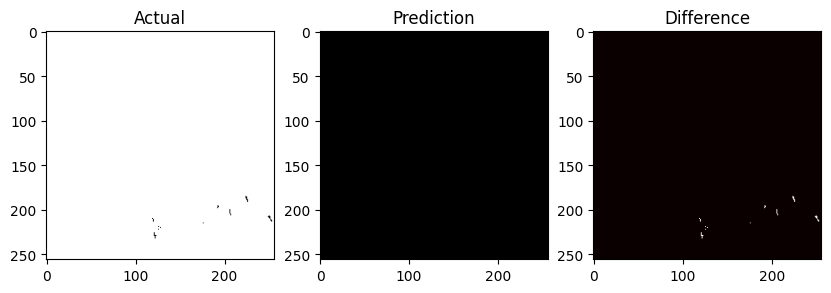

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(mask_bin, cmap='gray')
plt.title("Actual")

plt.subplot(1,3,2)
plt.imshow(pred_bin, cmap='gray')
plt.title("Prediction")

plt.subplot(1,3,3)
plt.imshow(diff, cmap='hot')
plt.title("Difference")

plt.show()

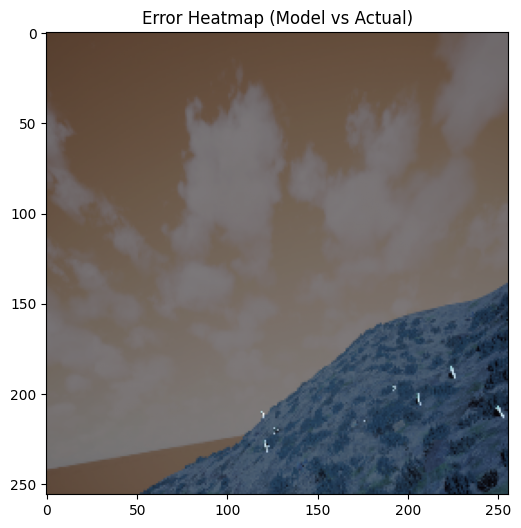

In [ ]:
plt.figure(figsize=(6,6))

plt.imshow(img)
plt.imshow(diff, cmap='hot', alpha=0.5)

plt.title("Error Heatmap (Model vs Actual)")
plt.show()

In [ ]:
import cv2

# after prediction
pred_bin = (pred_raw > 0.2).astype("uint8")

# smooth mask
pred_smooth = cv2.medianBlur(pred_bin.astype("uint8"), 5)

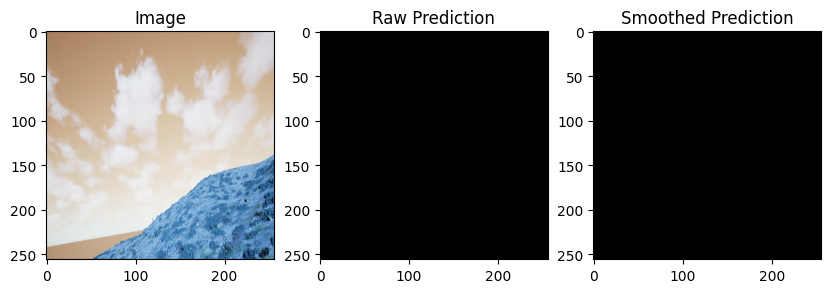

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(pred_bin, cmap='gray')
plt.title("Raw Prediction")

plt.subplot(1,3,3)
plt.imshow(pred_smooth, cmap='gray')
plt.title("Smoothed Prediction")

plt.show()

In [ ]:
pred_bin = (pred_raw > 0.05).astype("uint8")

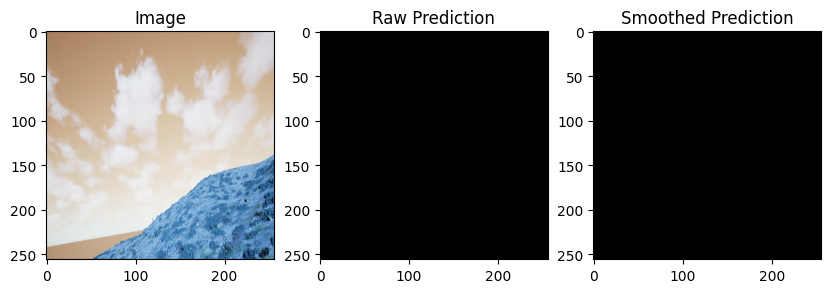

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,3,2)
plt.imshow(pred_bin, cmap='gray')
plt.title("Raw Prediction")

plt.subplot(1,3,3)
plt.imshow(pred_smooth, cmap='gray')
plt.title("Smoothed Prediction")

plt.show()

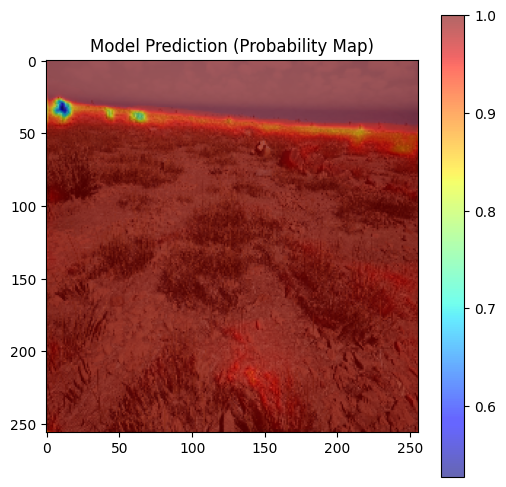

In [ ]:
plt.figure(figsize=(6,6))

plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
plt.imshow(pred_raw, cmap='jet', alpha=0.6)

plt.title("Model Prediction (Probability Map)")
plt.colorbar()

plt.show()

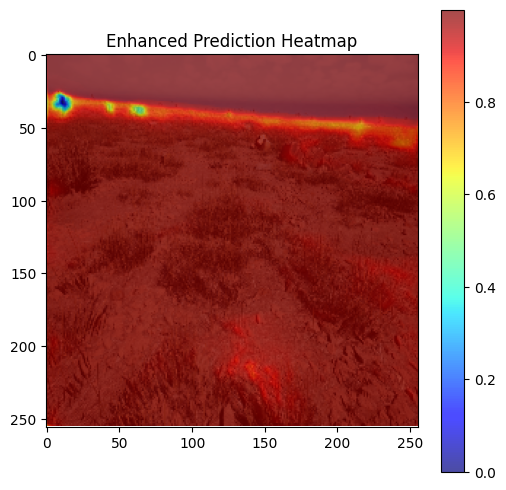

In [ ]:
import numpy as np

# normalize prediction for better visualization
pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)

plt.figure(figsize=(6,6))

plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
plt.imshow(pred_vis, cmap='jet', alpha=0.7)

plt.title("Enhanced Prediction Heatmap")
plt.colorbar()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


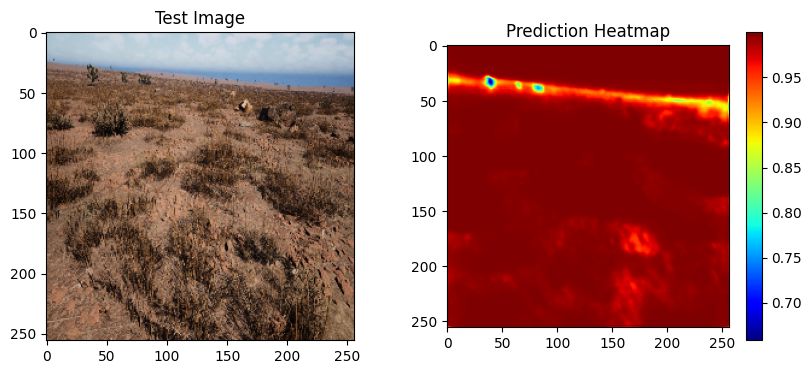

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


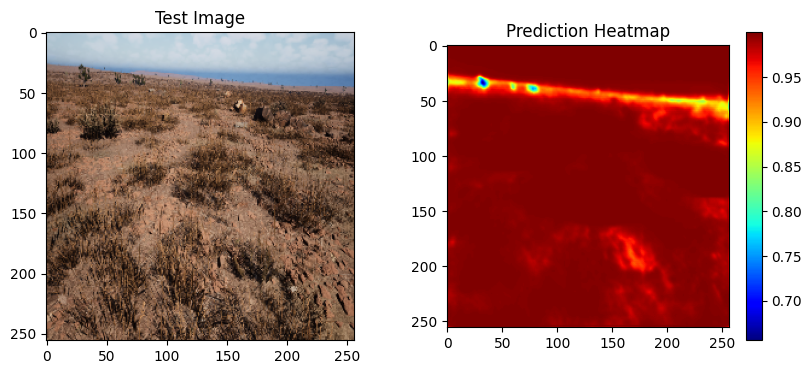

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


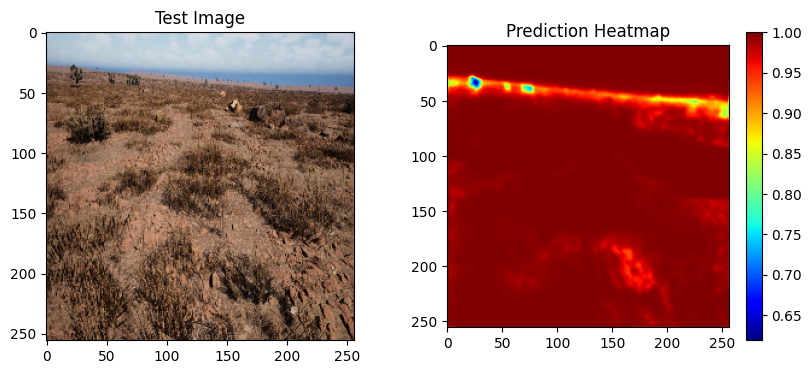

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


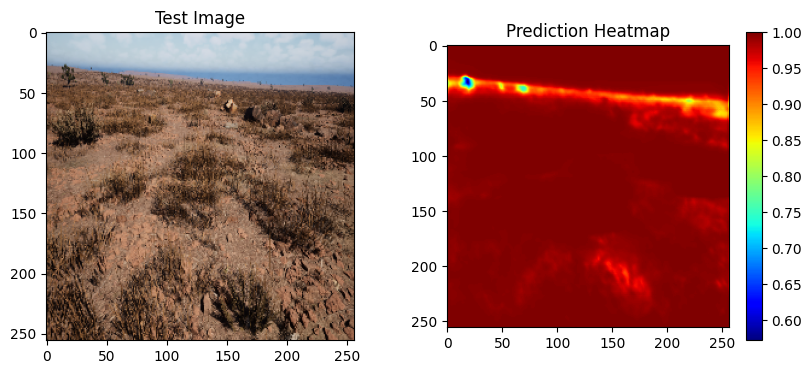

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


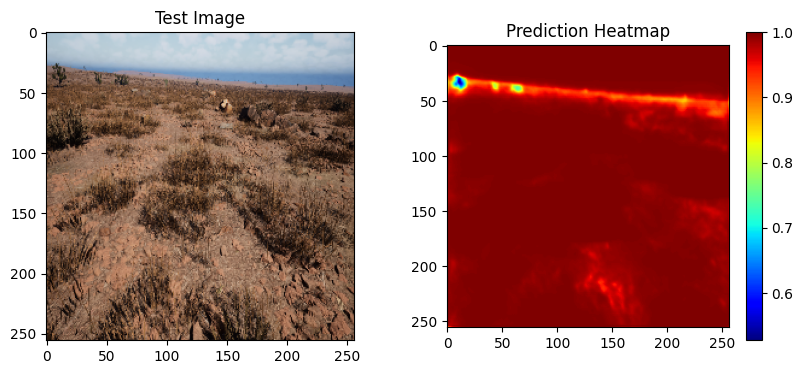

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

for img_name in test_images[:5]:
    img_path = os.path.join(test_path, img_name)
    
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    plt.figure(figsize=(10,4))
    
    # original image
    plt.subplot(1,2,1)
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.title("Test Image")
    
    # heatmap
    plt.subplot(1,2,2)
    plt.imshow(pred_raw, cmap='jet')   # KEY LINE
    plt.colorbar()
    plt.title("Prediction Heatmap")
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


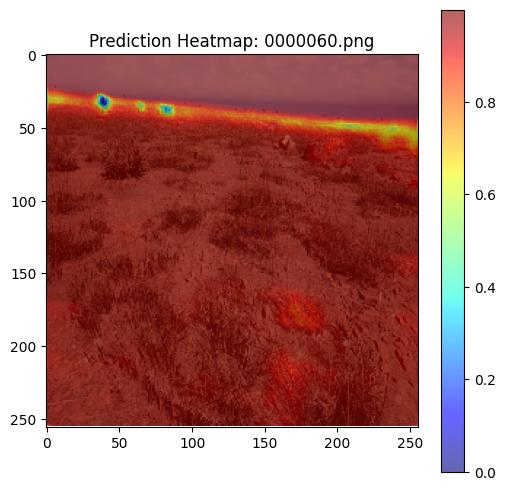

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


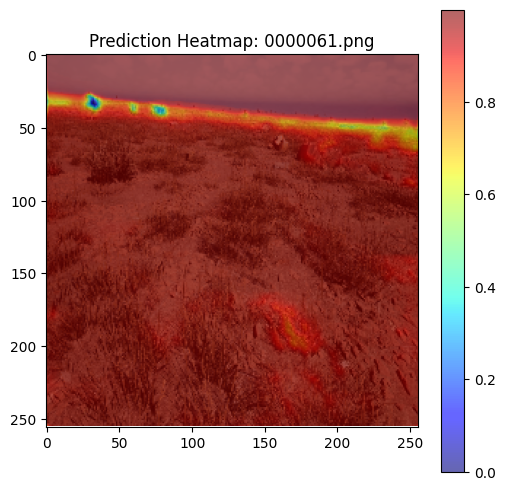

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


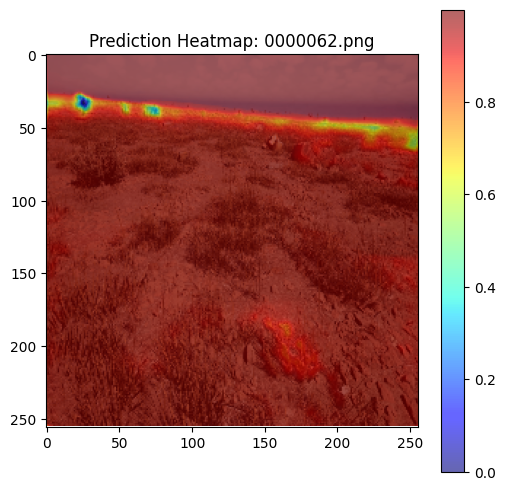

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


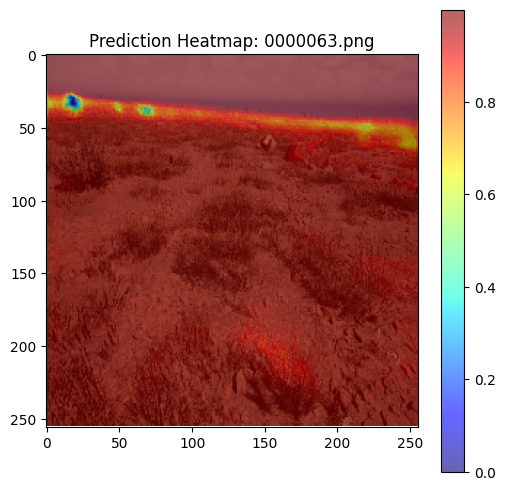

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


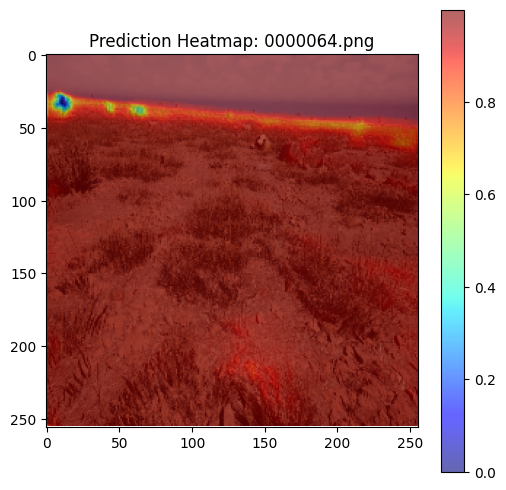

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


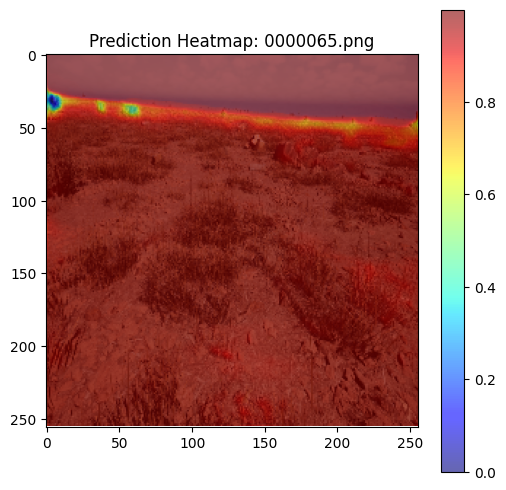

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

# show 6 different images
for img_name in test_images[:6]:
    img_path = os.path.join(test_path, img_name)
    
    # read + preprocess
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    # prediction
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    # enhance for visualization
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    # plot
    plt.figure(figsize=(6,6))
    
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.imshow(pred_vis, cmap='jet', alpha=0.6)
    
    plt.title(f"Prediction Heatmap: {img_name}")
    plt.colorbar()
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


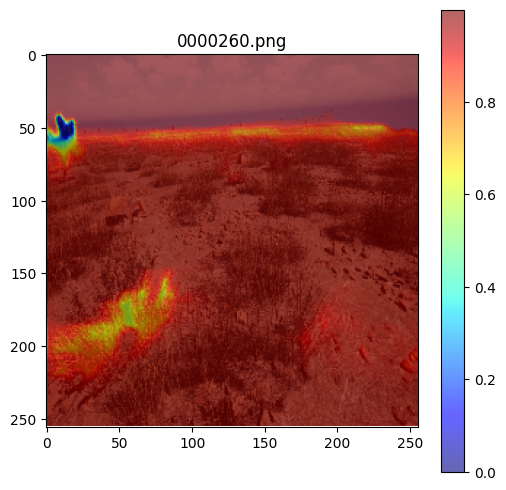

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


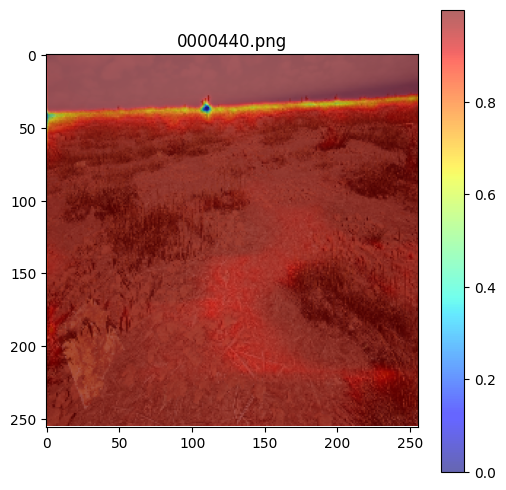

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


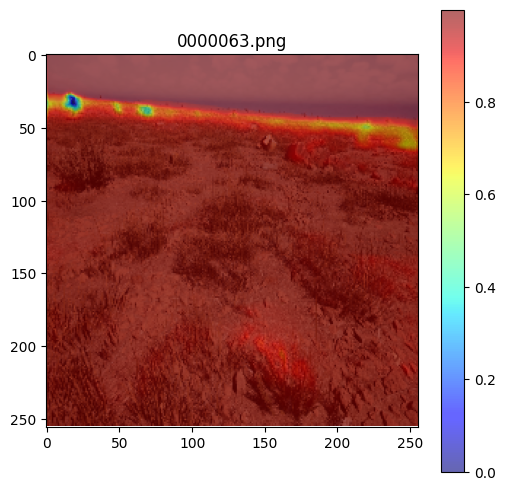

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


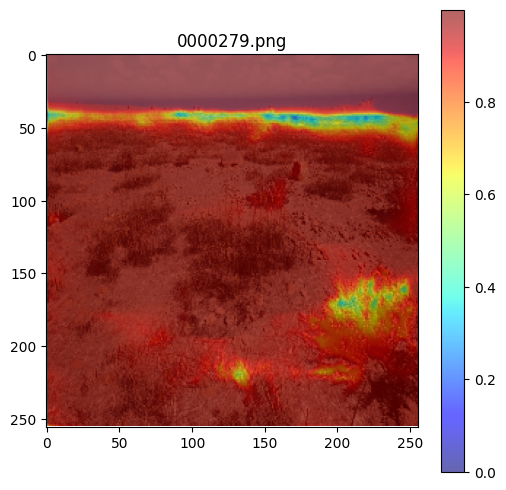

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


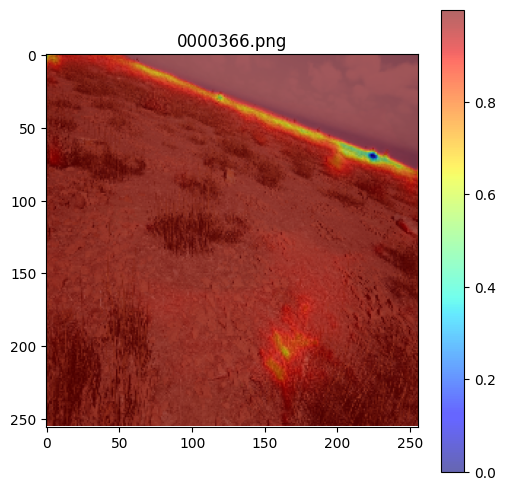

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


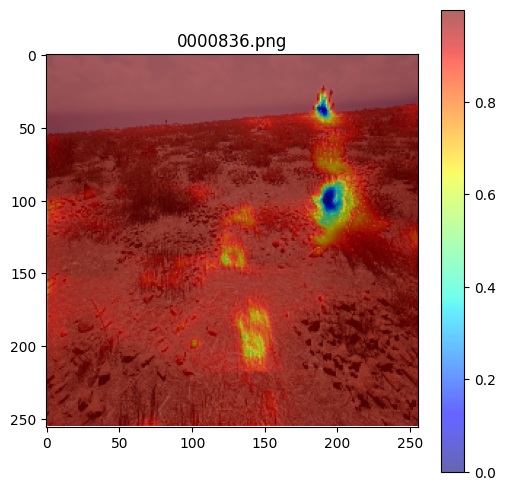

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

# pick 6 random images every run
random_images = random.sample(test_images, 6)

for img_name in random_images:
    img_path = os.path.join(test_path, img_name)
    
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    # enhance visualization
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(6,6))
    
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.imshow(pred_vis, cmap='jet', alpha=0.6)
    
    plt.title(f"{img_name}")
    plt.colorbar()
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


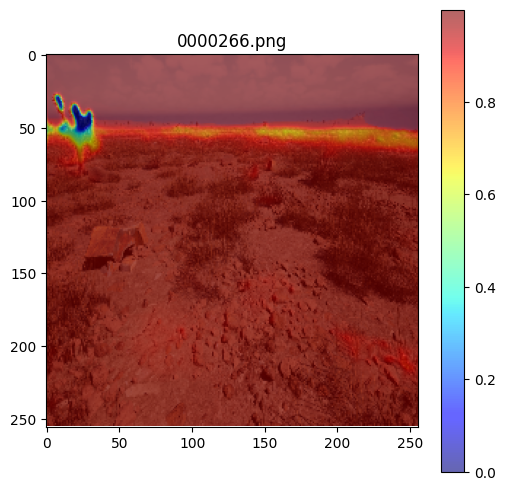

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


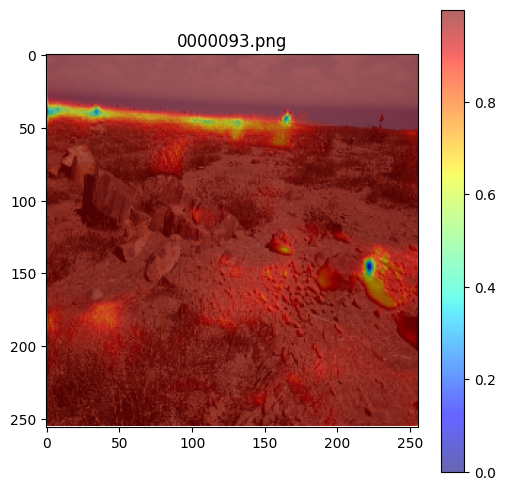

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


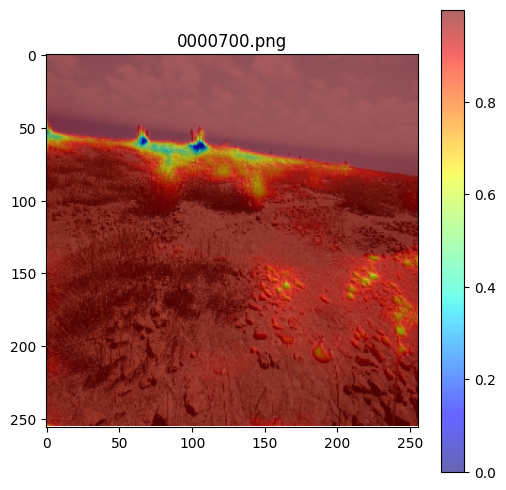

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


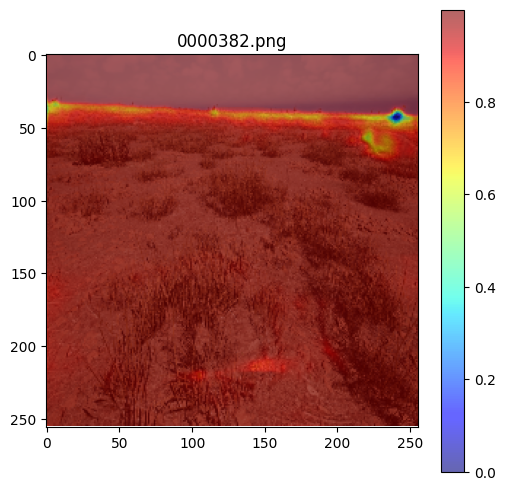

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


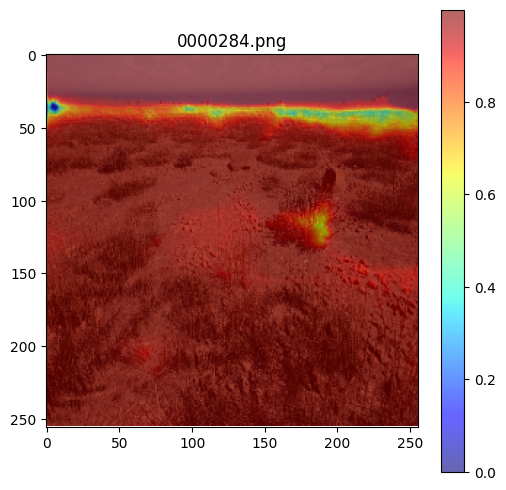

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


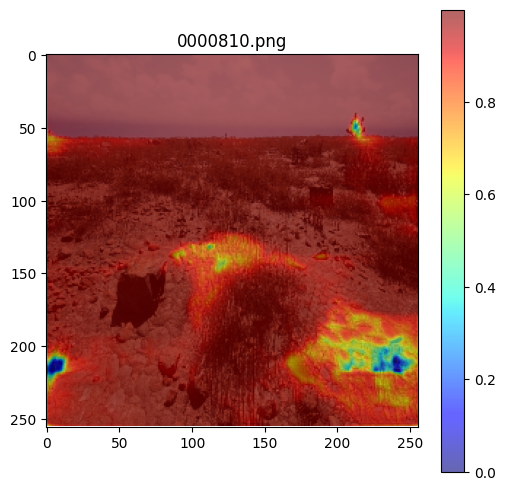

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

# pick 6 random images every run
random_images = random.sample(test_images, 6)

for img_name in random_images:
    img_path = os.path.join(test_path, img_name)
    
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    # enhance visualization
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(6,6))
    
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.imshow(pred_vis, cmap='jet', alpha=0.6)
    
    plt.title(f"{img_name}")
    plt.colorbar()
    
    plt.show()

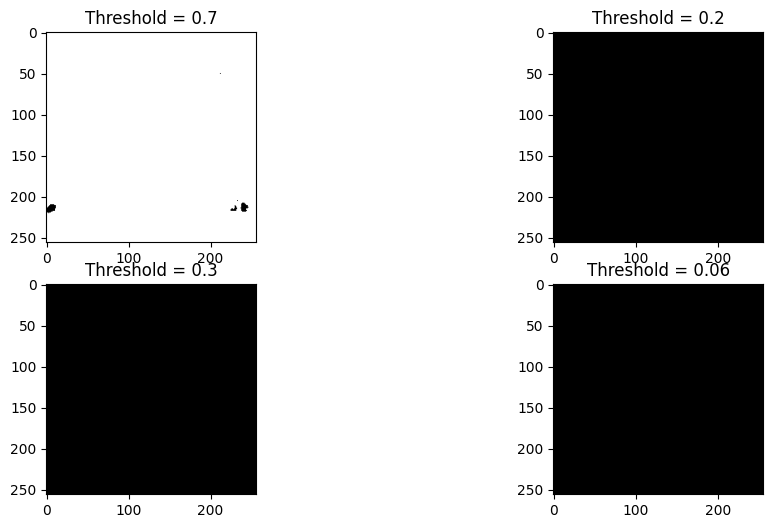

In [ ]:
thresholds = [0.7, 0.2, 0.3, 0.06]

plt.figure(figsize=(12,6))

for i, t in enumerate(thresholds):
    pred_bin = (pred_raw > t).astype("uint8")
    
    plt.subplot(2,2,i+1)
    plt.imshow(pred_bin, cmap='gray')
    plt.title(f"Threshold = {t}")




1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


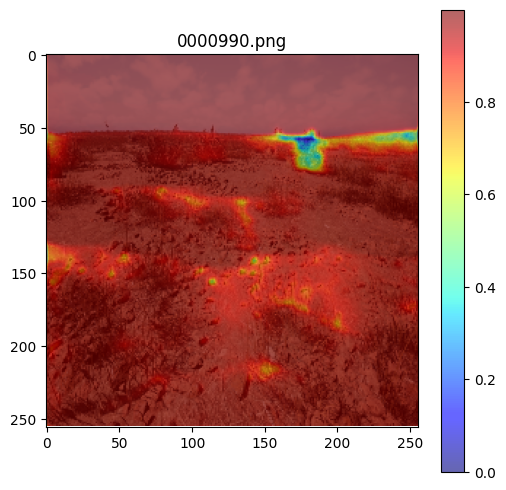

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


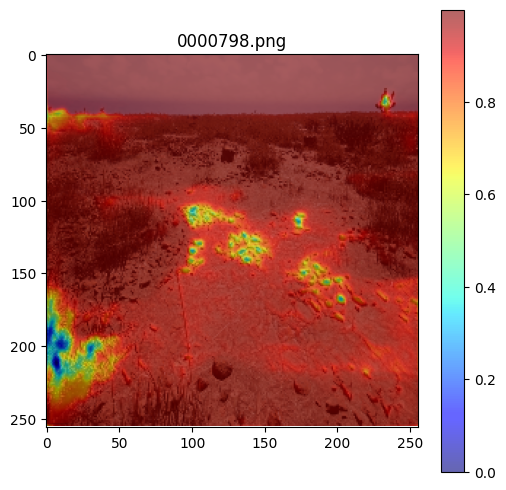

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


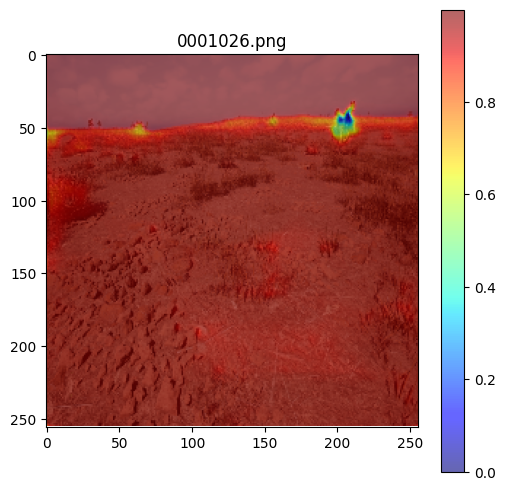

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


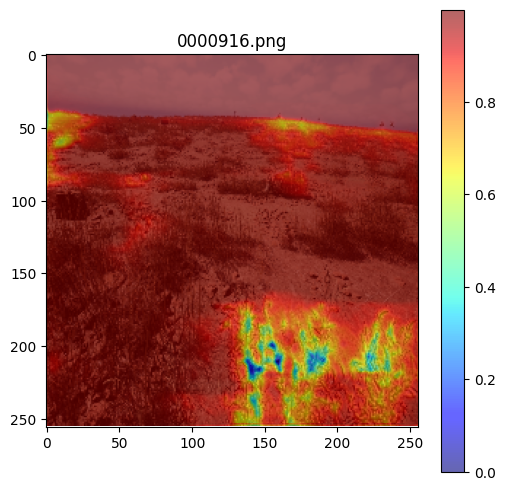

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


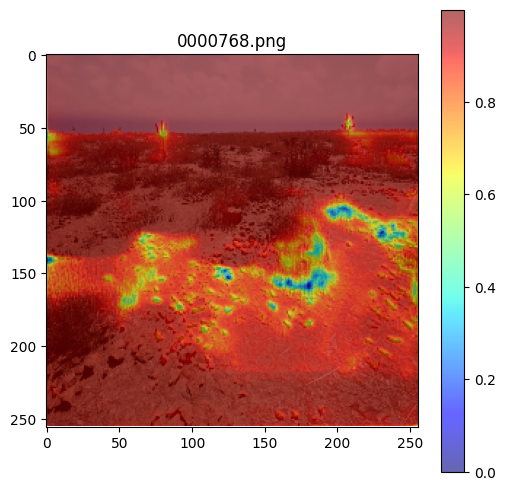

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


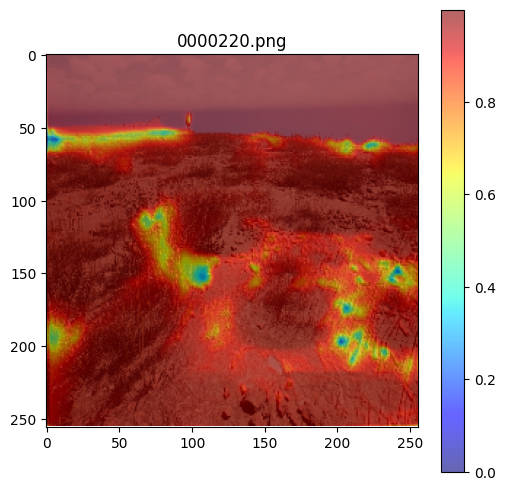

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

# pick 6 random images every run
random_images = random.sample(test_images, 6)

for img_name in random_images:
    img_path = os.path.join(test_path, img_name)
    
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    # enhance visualization
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(6,6))
    
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.imshow(pred_vis, cmap='jet', alpha=0.6)
    
    plt.title(f"{img_name}")
    plt.colorbar()
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


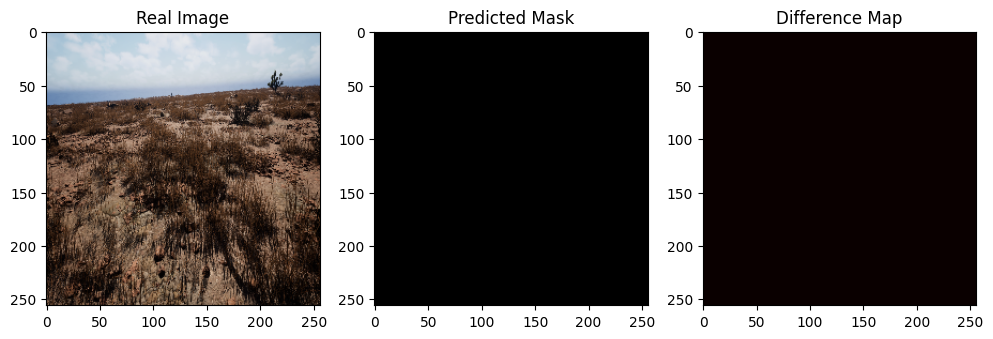

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


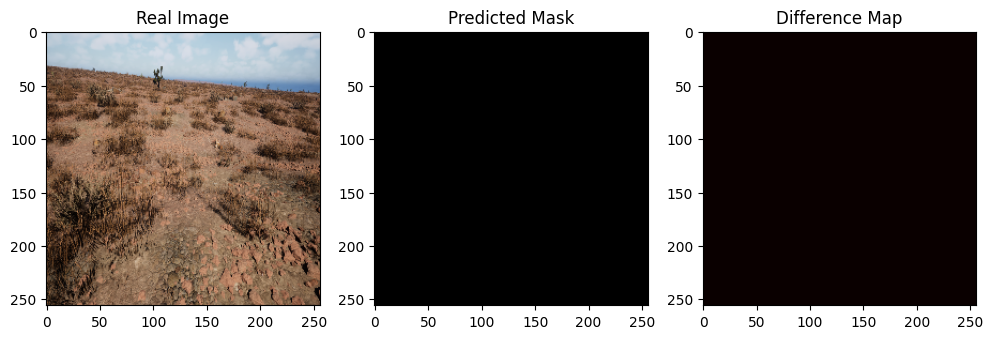

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


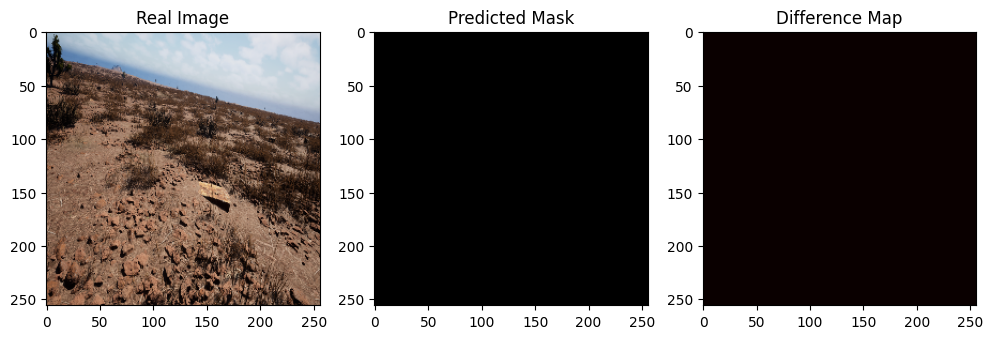

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


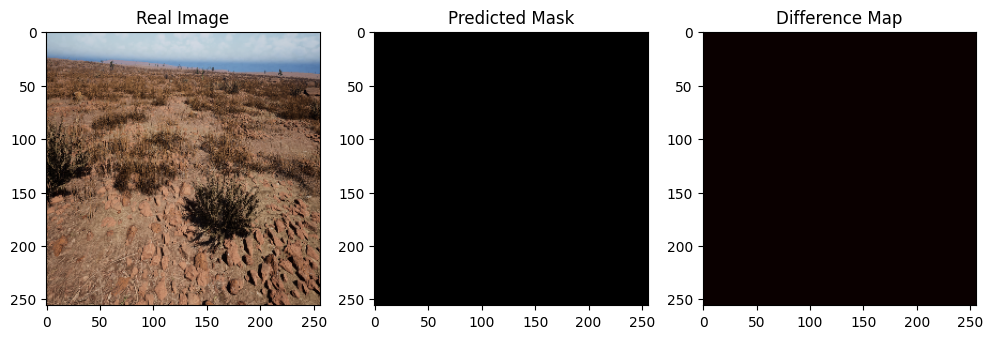

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

# pick random images
random_images = random.sample(test_images, 4)

THRESHOLD = 0.1   # best for your case (captures more regions)

for img_name in random_images:
    img_path = os.path.join(test_path, img_name)
    
    # read image
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    # prediction
    pred = model.predict(img_norm.reshape(1, 256, 256, 3))[0]
    pred_raw = pred.squeeze()
    
    # binary prediction
    pred_bin = (pred_raw > THRESHOLD).astype("uint8")
    
    # fake ground truth for demo (just show difference style)
    # since test has no mask, we compare with thresholded version itself
    diff = np.abs(pred_bin - (pred_raw > 0.2).astype("uint8"))
    
    # plot
    plt.figure(figsize=(12,4))
    
    # real image
    plt.subplot(1,3,1)
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.title("Real Image")
    
    # predicted mask
    plt.subplot(1,3,2)
    plt.imshow(pred_bin, cmap='gray')
    plt.title("Predicted Mask")
    
    # difference map
    plt.subplot(1,3,3)
    plt.imshow(diff, cmap='hot')
    plt.title("Difference Map")
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


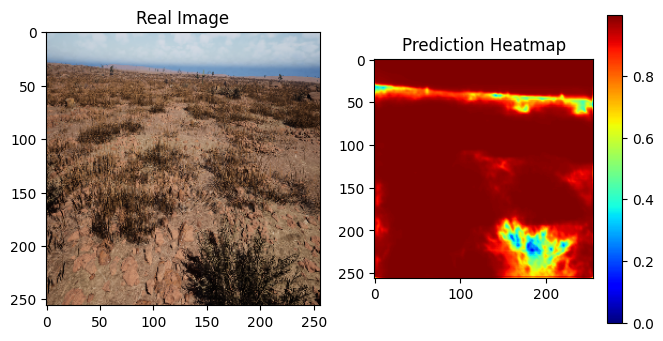

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


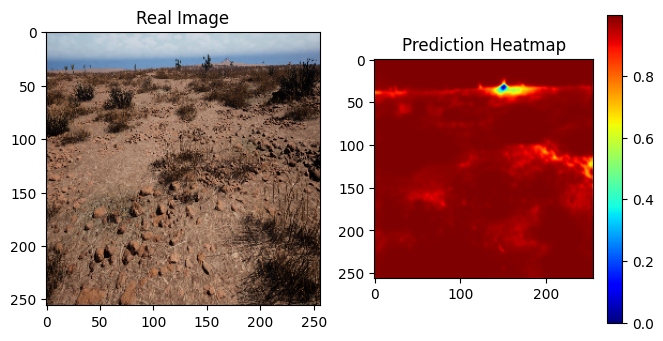

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


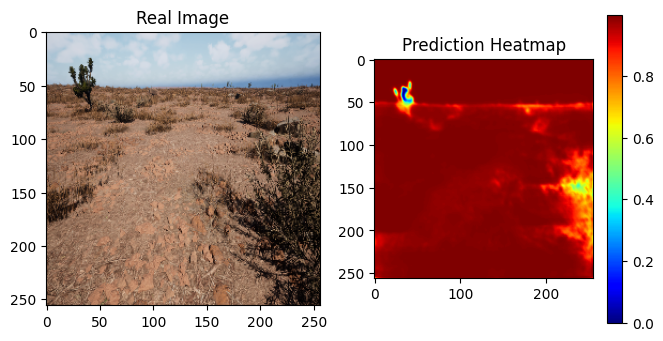

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

test_path = "dataset/test/Color_Images"
test_images = os.listdir(test_path)

random_images = random.sample(test_images, 3)

THRESHOLD = 0.1

for img_name in random_images:
    img_path = os.path.join(test_path, img_name)
    
    img = cv2.imread(img_path)
    img_resized = cv2.resize(img, (256, 256))
    img_norm = img_resized / 255.0
    
    pred = model.predict(img_norm.reshape(1,256,256,3))[0]
    pred_raw = pred.squeeze()
    
    pred_bin = (pred_raw > THRESHOLD).astype("uint8")
    
    # normalize heatmap
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(12,4))
    
    # real image
    plt.subplot(1,3,1)
    plt.imshow(cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB))
    plt.title("Real Image")
    
    # heatmap (important)
    plt.subplot(1,3,2)
    plt.imshow(pred_vis, cmap='jet')
    plt.title("Prediction Heatmap")
    plt.colorbar()
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


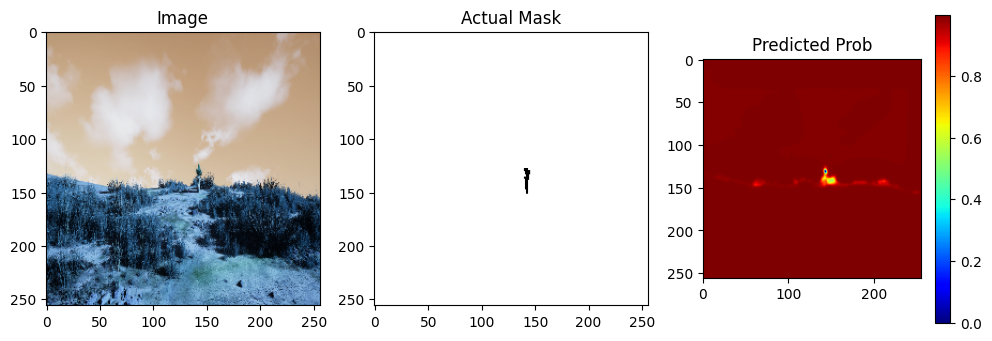

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step


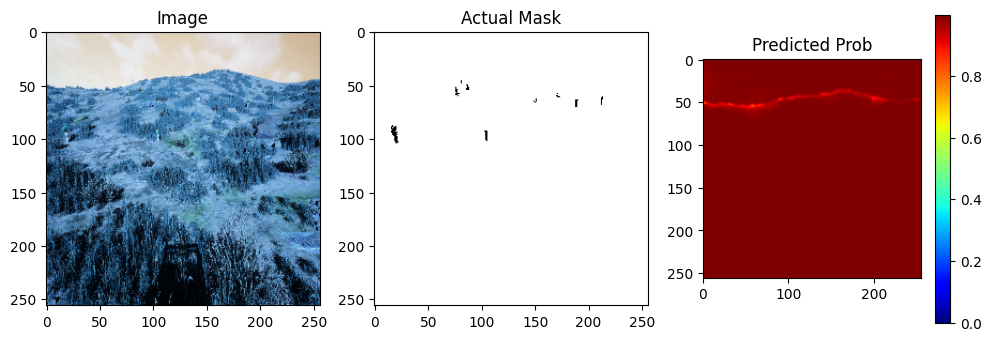

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


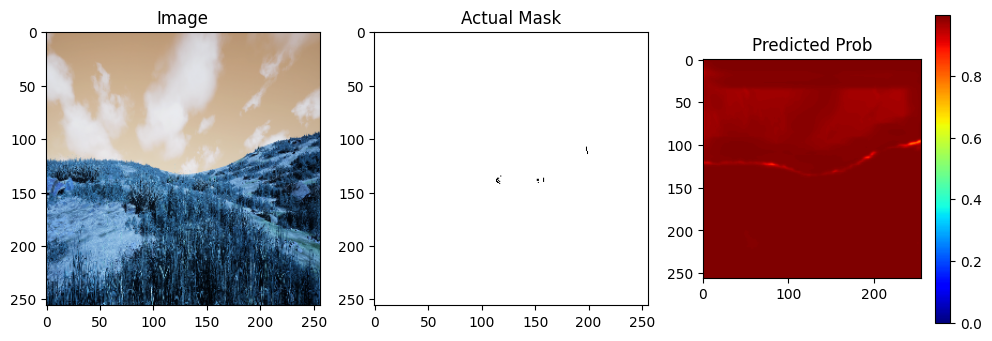

In [ ]:
import matplotlib.pyplot as plt
import random

# pick 3 random samples from train
indices = random.sample(range(len(train_df)), 3)

for i in indices:
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred_raw = pred.squeeze()
    
    # normalize for better view
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(12,4))
    
    # image
    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Image")
    
    # actual mask
    plt.subplot(1,3,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Actual Mask")
    
    # prediction probability
    plt.subplot(1,3,3)
    plt.imshow(pred_vis, cmap='jet')
    plt.title("Predicted Prob")
    plt.colorbar()
    
    plt.show()

Text(0.5, 1.0, 'Overlay Prediction')

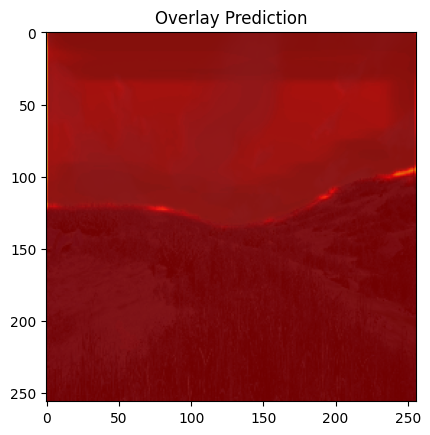

In [ ]:
plt.imshow(img)
plt.imshow(pred_vis, cmap='jet', alpha=0.9)
plt.title("Overlay Prediction")

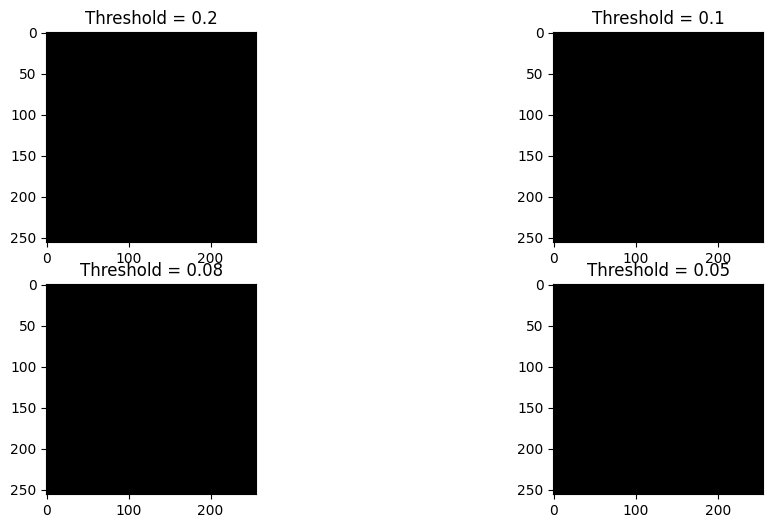

In [ ]:
thresholds = [0.2, 0.1, 0.08, 0.05]

plt.figure(figsize=(12,6))

for i, t in enumerate(thresholds):
    pred_bin = (pred_raw > t).astype("uint8")
    
    plt.subplot(2,2,i+1)
    plt.imshow(pred_bin, cmap='gray')
    plt.title(f"Threshold = {t}")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


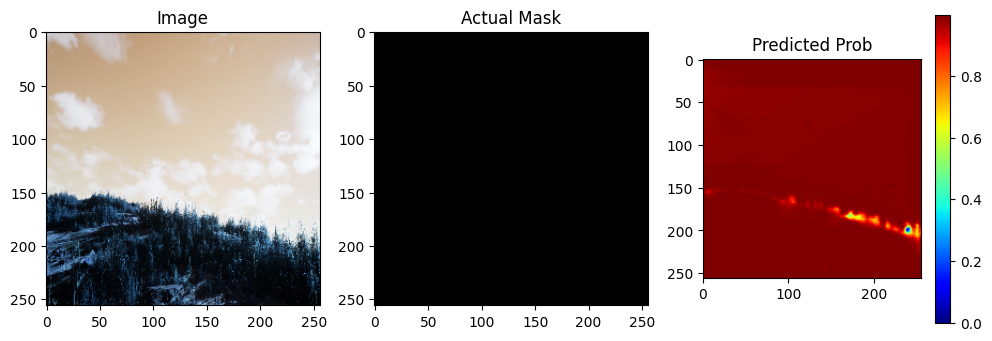

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


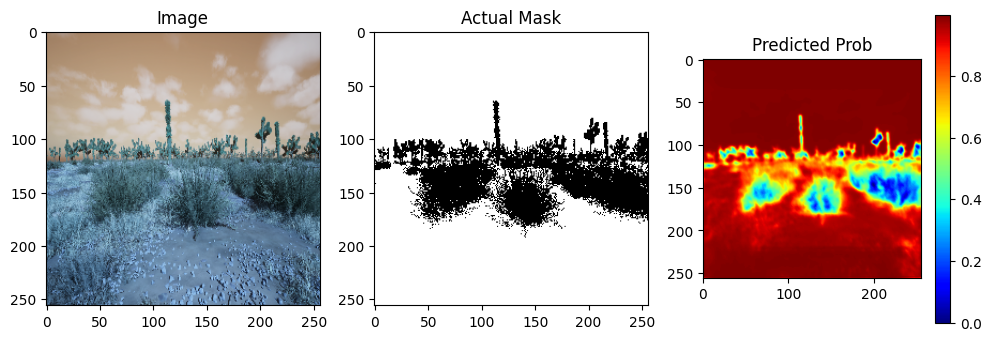

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step


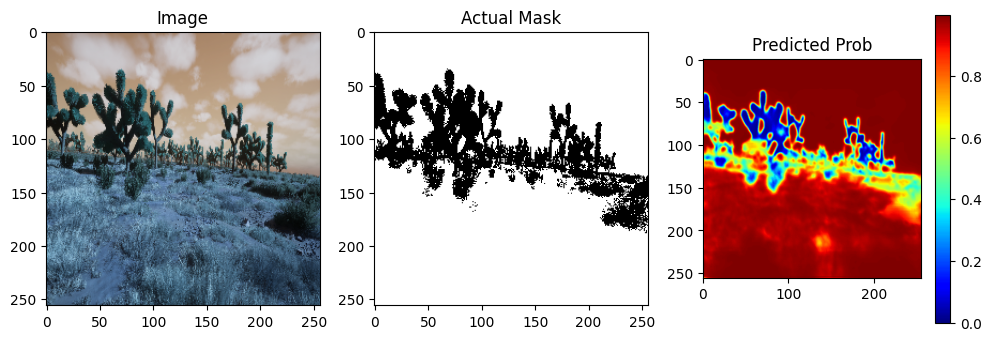

In [ ]:
import matplotlib.pyplot as plt
import random

# pick 3 random samples from train
indices = random.sample(range(len(train_df)), 3)

for i in indices:
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred_raw = pred.squeeze()
    
    # normalize for better view
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(12,4))
    
    # image
    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Image")
    
    # actual mask
    plt.subplot(1,3,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Actual Mask")
    
    # prediction probability
    plt.subplot(1,3,3)
    plt.imshow(pred_vis, cmap='jet')
    plt.title("Predicted Prob")
    plt.colorbar()
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


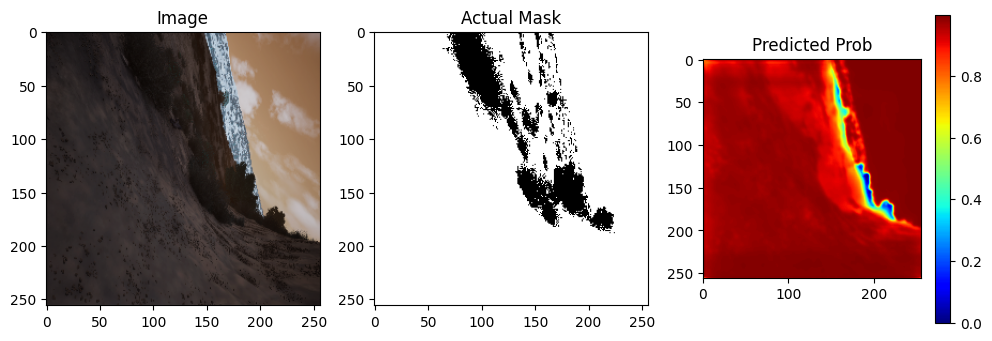

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


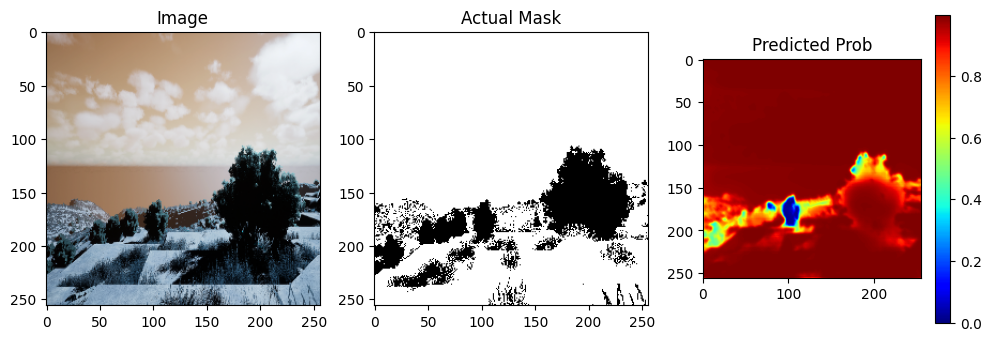

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


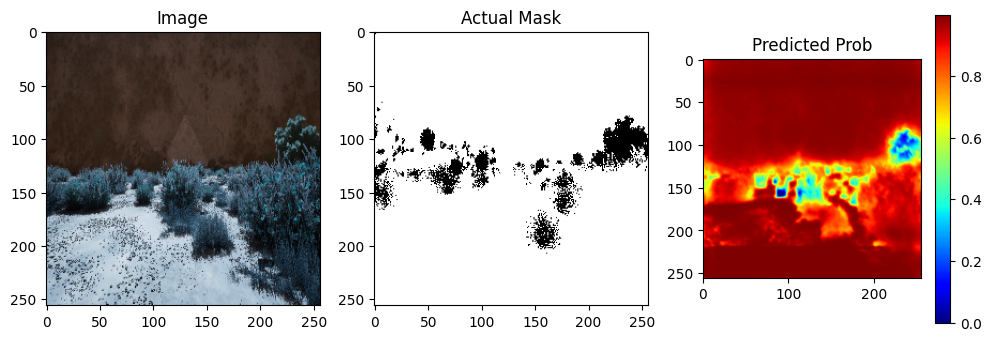

In [ ]:
import matplotlib.pyplot as plt
import random

# pick 3 random samples from train
indices = random.sample(range(len(train_df)), 3)

for i in indices:
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred_raw = pred.squeeze()
    
    # normalize for better view
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(12,4))
    
    # image
    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Image")
    
    # actual mask
    plt.subplot(1,3,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Actual Mask")
    
    # prediction probability
    plt.subplot(1,3,3)
    plt.imshow(pred_vis, cmap='jet')
    plt.title("Predicted Prob")
    plt.colorbar()
    
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


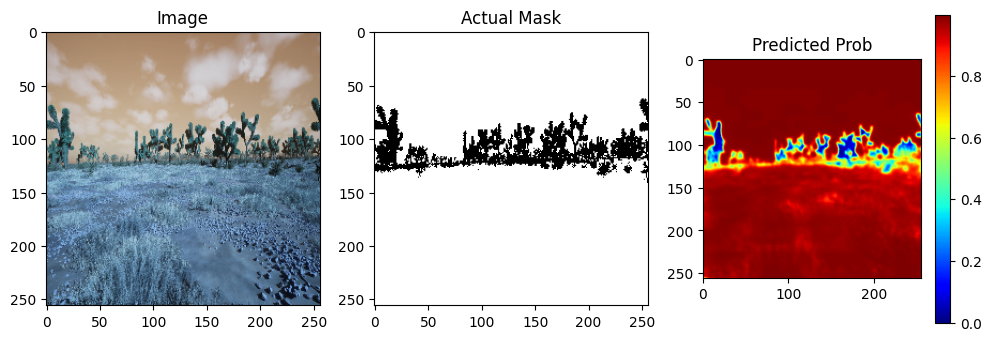

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


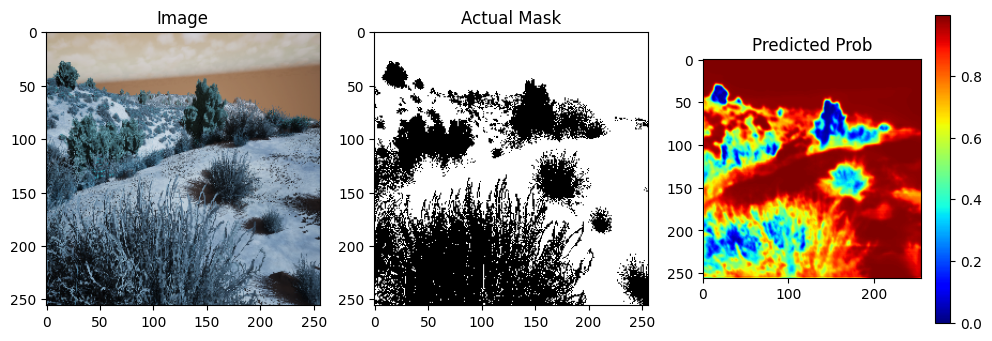

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step


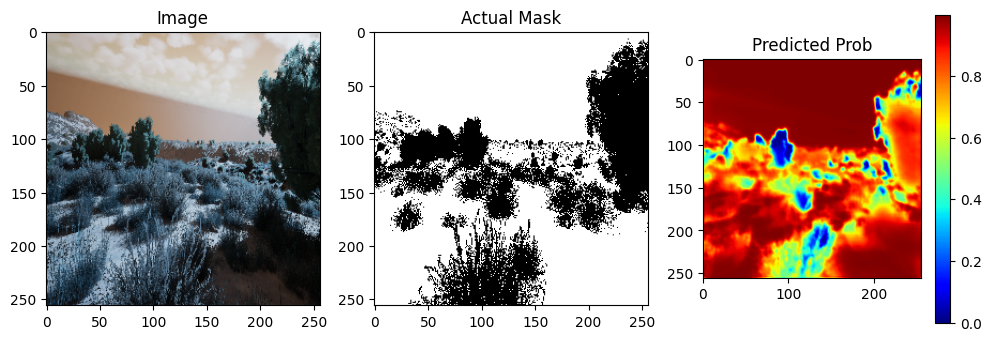

In [ ]:
import matplotlib.pyplot as plt
import random

# pick 3 random samples from train
indices = random.sample(range(len(train_df)), 3)

for i in indices:
    img, mask = preprocess(train_df.loc[i, "image"], train_df.loc[i, "mask"])
    
    pred = model.predict(img.reshape(1,256,256,3))[0]
    pred_raw = pred.squeeze()
    
    # normalize for better view
    pred_vis = (pred_raw - pred_raw.min()) / (pred_raw.max() - pred_raw.min() + 1e-6)
    
    plt.figure(figsize=(12,4))
    
    # image
    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Image")
    
    # actual mask
    plt.subplot(1,3,2)
    plt.imshow(mask, cmap='gray')
    plt.title("Actual Mask")
    
    # prediction probability
    plt.subplot(1,3,3)
    plt.imshow(pred_vis, cmap='jet')
    plt.title("Predicted Prob")
    plt.colorbar()
    
    plt.show()

In [ ]:
print('hello World')